In [1]:
# ============================================================
# VISIONPORT - DEEP LEARNING OBJECT DETECTION
# Experiment: Project Orientation and Lifecycle Mapping
# Model: YOLOv8
# CELL 1: INSTALL LIBRARIES
# ============================================================
!pip install -q -U ultralytics

In [2]:
# CELL 2: IMPORT LIBRARIES
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
       VISIONPORT OBJECT DETECTION SYSTEM


In [9]:
# CELL 3: UPLOAD A REAL IMAGE
import requests

url = "https://ultralytics.com/images/bus.jpg"
# other option: "https://ultralytics.com/images/zidane.jpg"
image_path = "input.jpg"

r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
r.raise_for_status()
with open(image_path, "wb") as f:
    f.write(r.content)
print("Saved:", image_path)

Saved: input.jpg


In [10]:
# CELL 4: LOAD YOLO MODEL
print("Loading YOLOv8 pretrained model...")
model = YOLO("yolov8n.pt")
print("Model loaded successfully!")

Loading YOLOv8 pretrained model...
Model loaded successfully!


In [11]:
# CELL 5: IMAGE PREPROCESSING
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded! Please upload a valid image file.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image Acquisition Completed")
print("Original Image Size:", image_rgb.shape)

Image Acquisition Completed
Original Image Size: (1080, 810, 3)


In [12]:
# CELL 6: OBJECT DETECTION / INFERENCE
print("Performing Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)

# Draw bounding boxes (plot() returns BGR -> convert to RGB for matplotlib)
output_image = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)

Performing Object Detection...


In [13]:
# CELL 7: DISPLAY DETECTED OBJECTS
print("OBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes
total_objects = len(boxes) if boxes is not None else 0

if total_objects > 0:
    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")
else:
    print("No objects detected.")

OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: bus
   Confidence: 87.34%
   Bounding Box: (22, 231, 805, 756)
2. Object: person
   Confidence: 86.57%
   Bounding Box: (48, 398, 245, 902)
3. Object: person
   Confidence: 85.28%
   Bounding Box: (669, 392, 809, 877)
4. Object: person
   Confidence: 82.52%
   Bounding Box: (221, 405, 344, 857)
5. Object: person
   Confidence: 26.11%
   Bounding Box: (0, 550, 63, 873)
6. Object: stop sign
   Confidence: 25.51%
   Bounding Box: (0, 254, 32, 324)


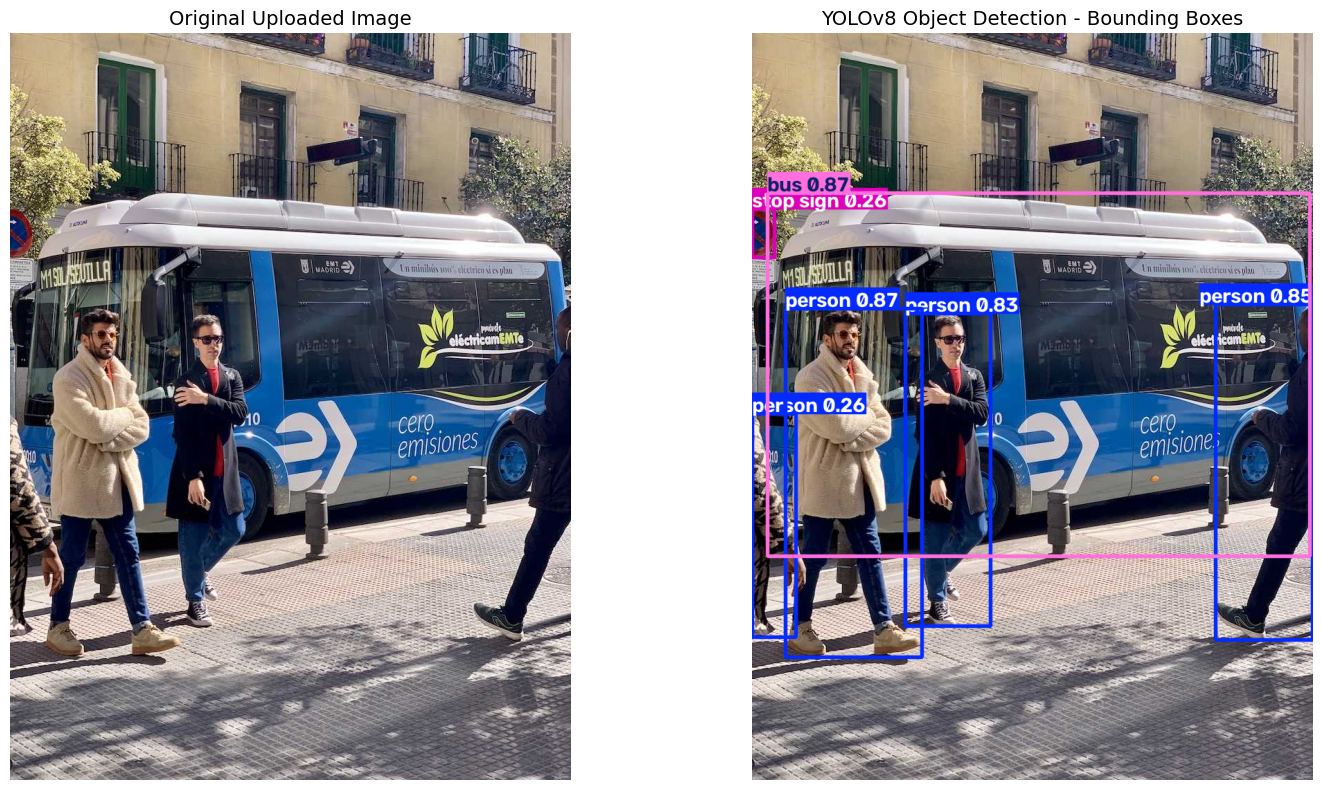

In [14]:
# CELL 8: DISPLAY ORIGINAL AND DETECTED IMAGE
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection - Bounding Boxes", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# CELL 9: SAVE DETECTED IMAGE
output_path = "VisionPort_Detection_Output.jpg"
cv2.imwrite(output_path, cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR))
print("Saved:", output_path)

Saved: VisionPort_Detection_Output.jpg


In [16]:
# CELL 10: FINAL SYSTEM REPORT
print("=" * 60)
print("           VISIONPORT SYSTEM REPORT")
print("=" * 60)
print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")
print("Object Detection        : SUCCESS")
print("Bounding Box Generation : SUCCESS")
print("Output Visualization    : SUCCESS")
print("Total Objects Detected  :", total_objects)
print("=" * 60)
print("VISIONPORT PIPELINE COMPLETED!")

           VISIONPORT SYSTEM REPORT
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation : SUCCESS
Output Visualization    : SUCCESS
Total Objects Detected  : 6
VISIONPORT PIPELINE COMPLETED!


In [17]:
# CELL 11: DOWNLOAD OUTPUT IMAGE
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>